# Simandou : que peut changer le fer pour l'économie guinéenne ? (scénarios 2026-2030)

**Question :** Simandou, le plus grand gisement de fer inexploité au monde, a commencé à exporter fin 2025. Que pèseraient ses exportations, et ce que touche l'État, une fois la mine à plein régime ?

**Méthode :** Simandou n'a pas encore d'historique de production. On ne peut donc pas l'analyser comme la bauxite. Je construis des **scénarios**, c'est-à-dire des hypothèses chiffrées et explicites, et je les compare aux chiffres réels mesurés aux étapes 1 à 3.

**Données :**
- `data/simandou.csv` : 22 faits publiés (capacité, calendrier, investissement, parts de l'État, ventes 2026), chacun avec sa source et son lien (Rio Tinto, Ecofin, SteelOrbis, Code minier).
- `data/prix_fer.csv` : prix du minerai de fer, Banque mondiale (Commodity Markets Outlook, avril 2026).
- `data/hypotheses_simandou.csv` : **mes hypothèses** (montée en charge, trois prix, taxe), séparées des faits pour pouvoir les changer sans toucher au code.

Requêtes : `sql/04_*.sql`.

In [1]:
import sys
sys.path.append("..")

from src.requetes import requete
from src.graphiques import graphique_simandou_scenarios, graphique_simandou_comparaison

## 1. Ce qui est annoncé, et où en est le projet fin 2026

In [2]:
requete("04_faits_simandou").show(max_width=200)

┌────────────┬────────────────────────────┬────────┬───────────────┬──────────────────────────────────────────────┐
│    date    │         indicateur         │ valeur │     unite     │                    source                    │
│    date    │          varchar           │ double │    varchar    │                   varchar                    │
├────────────┼────────────────────────────┼────────┼───────────────┼──────────────────────────────────────────────┤
│ 2024-07-16 │ capacite_totale            │  120.0 │ Mt/an         │ Rio Tinto communiqué 16/07/2024              │
│ 2024-07-16 │ capacite_simfer            │   60.0 │ Mt/an         │ Rio Tinto communiqué 16/07/2024              │
│ 2024-07-16 │ capacite_wcs               │   60.0 │ Mt/an         │ Rio Tinto communiqué 16/07/2024              │
│ 2024-07-16 │ investissement_simfer      │   11.6 │ milliards USD │ Rio Tinto communiqué 16/07/2024              │
│ 2024-07-16 │ part_etat_simfer           │   15.0 │ %             │ Rio

**Constat :** à plein régime, Simandou doit exporter **120 millions de tonnes par an**, à parts égales entre SimFer (Rio Tinto et Chinalco) et WCS (Winning, Weiqiao, Baowu). L'État guinéen détient 15 % de chaque mine et 15 % du rail et du port.

La réalité de 2026 est plus lente que les annonces. SimFer n'a vendu que **1,7 Mt** de janvier à septembre, alors que Rio Tinto prévoit 5 à 10 Mt sur l'année. L'objectif de 60 Mt pour SimFer est fixé au second semestre 2028.

## 2. Les hypothèses du scénario

In [3]:
requete("04_hypotheses").show(max_width=200)

┌─────────┬────────────────┬────────┬─────────┬───────────────────────────────────────────────────────────────────────────────────────────────────────┐
│  type   │      cle       │ valeur │  unite  │                                             justification                                             │
│ varchar │    varchar     │ double │ varchar │                                                varchar                                                │
├─────────┼────────────────┼────────┼─────────┼───────────────────────────────────────────────────────────────────────────────────────────────────────┤
│ volume  │ 2026           │    7.5 │ Mt      │ milieu de la prévision de ventes de Rio Tinto (5 à 10 Mt)                                             │
│ volume  │ 2027           │   25.0 │ Mt      │ hypothèse : montée en charge progressive de SimFer et de WCS                                          │
│ volume  │ 2028           │   60.0 │ Mt      │ hypothèse : SimFer atteint 60 Mt/an au s

Trois prix pour encadrer l'incertitude :
- **Moyen, 97 $/t :** la prévision 2026 de la Banque mondiale.
- **Haut, 110 $/t :** le niveau de 2024.
- **Bas, 80 $/t :** il traduit un risque réel. En ajoutant jusqu'à 120 Mt de fer de haute qualité sur le marché mondial, Simandou peut lui-même faire baisser les prix.

## 3. La valeur des exportations, 2026-2030

,annee,scenario,millions_tonnes,usd_par_tonne,milliards_usd
0,2026,bas,7.5,80.0,0.60
1,2026,moyen,7.5,97.0,0.73
2,2026,haut,7.5,110.0,0.82
3,2027,bas,25.0,80.0,2.00
4,2027,moyen,25.0,97.0,2.42
5,2027,haut,25.0,110.0,2.75
6,2028,bas,60.0,80.0,4.80
7,2028,moyen,60.0,97.0,5.82
8,2028,haut,60.0,110.0,6.60
9,2029,bas,100.0,80.0,8.00


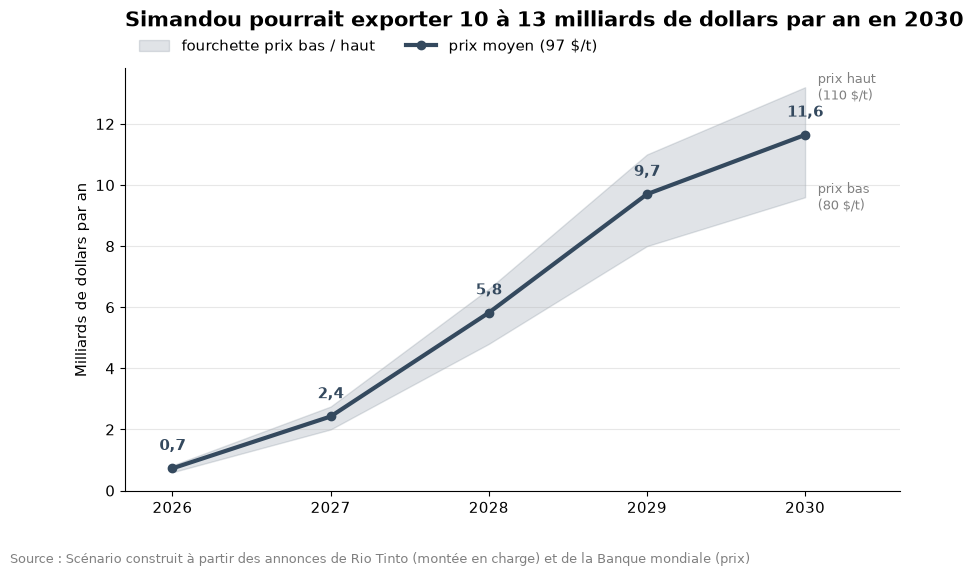

In [4]:
scenarios = requete("04_scenarios_exportations").df()
display(scenarios.round(2))
graphique_simandou_scenarios(scenarios)

**Conclusion :** en 2026, Simandou ne pèse encore presque rien (moins d'un milliard de dollars). Si la montée en charge suit les objectifs annoncés, ses exportations atteindraient **5 à 7 milliards en 2028**, puis **10 à 13 milliards de dollars par an en 2030**, selon le prix du fer.

## 4. Comparé à la bauxite et au PIB

,element,milliards_usd
0,PIB de la Guinée (2025),28.35
1,Bauxite achetée par le monde (2025),12.96
2,"Simandou à 120 Mt, prix bas",9.60
3,"Simandou à 120 Mt, prix moyen",11.64
4,"Simandou à 120 Mt, prix haut",13.20


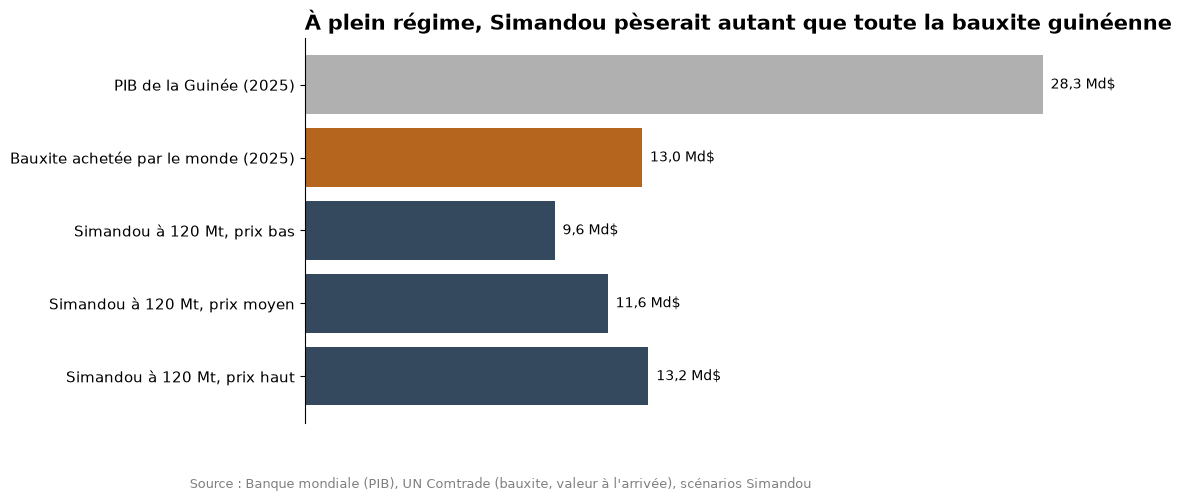

In [5]:
comparaison = requete("04_comparaison_plein_regime").df()
display(comparaison.round(2))
graphique_simandou_comparaison(comparaison)

**Conclusion :** à plein régime et au prix moyen, Simandou exporterait environ **11,6 milliards de dollars par an**. C'est presque autant que toute la bauxite achetée à la Guinée en 2025 (13,0 milliards). Les exportations minières du pays doubleraient presque.

**Attention :** ce montant équivaut à 41 % du PIB de 2025, mais il **ne s'ajoute pas** au PIB. Une grande partie de la valeur repart à l'étranger : remboursement des 11,6 milliards investis rien que par SimFer, achats de matériel et dividendes des actionnaires, pour l'essentiel chinois. Ce qui reste en Guinée, ce sont les salaires, les achats locaux et les recettes de l'État (partie 5).

Les deux valeurs sont comparables : le prix du fer de la Banque mondiale et la valeur miroir de la bauxite sont tous deux des prix à l'arrivée en Chine.

## 5. Ce que l'État pourrait toucher

In [6]:
requete("04_recettes_etat").df().round(1)

,scenario_prix,usd_par_tonne,taxe_usd_par_tonne,taxe_fer_millions_usd,taxe_bauxite_2024_millions_usd
0,bas,80.0,2.4,288.0,352.3
1,moyen,97.0,2.9,349.2,352.3
2,haut,110.0,3.3,396.0,352.3


**Conclusion :** avec une taxe d'extraction de 3 %, l'État toucherait environ **290 à 400 millions de dollars par an** sur le fer de Simandou à plein régime. C'est à peu près autant que la taxe minière payée par **toutes** les sociétés bauxitiques en 2024 (352 millions). Par tonne, c'est aussi comparable : environ 2,9 $ pour le fer, contre 2,4 $ en moyenne pour la bauxite.

S'y ajouteraient d'autres revenus, que je ne chiffre pas faute de données publiques :
- les **dividendes** liés aux 15 % de l'État dans les mines et dans le rail et le port ;
- l'**impôt sur les sociétés** (30 %), une fois les investissements amortis ;
- à terme, la propriété du rail et du port, qui reviennent à l'État après 35 ans.

## Ce qu'il faut retenir

1. **Simandou démarre lentement :** 1,7 Mt vendues fin septembre 2026, pour un objectif de 120 Mt/an. Le plein régime n'est pas attendu avant 2029-2030.
2. **À plein régime, c'est une deuxième bauxite :** 10 à 13 milliards de dollars d'exportations par an. Les exportations minières de la Guinée doubleraient presque.
3. **Pour l'État, l'effet est plus modeste :** environ 350 millions de dollars de taxe d'extraction par an au prix moyen. C'est autant que toute la taxe minière sur la bauxite aujourd'hui, mais ce n'est pas un doublement du PIB.
4. **La dépendance à la Chine augmente :** les actionnaires de Simandou sont en majorité chinois (Chinalco, Baowu, Winning, Weiqiao), et le premier navire est parti vers la Chine. Après la bauxite (93 % vers la Chine, étape 3), le fer ajoute un deuxième produit vers le même client.

## Limites

- **Ce sont des scénarios, pas des prévisions.** La montée en charge 2027-2029 est une hypothèse construite à partir des objectifs annoncés, et ces objectifs ont déjà pris du retard en 2026.
- **Aucune donnée publique sur les volumes de WCS :** je suppose qu'elle suit le même rythme que SimFer.
- **La taxe est calculée sur le prix à l'arrivée en Chine.** Le Code minier retire le coût du fret et ajuste selon la teneur en fer (65 % ici, contre 62 % pour le prix de référence). Le montant réel peut donc être un peu plus bas. La convention propre à Simandou peut aussi prévoir un autre taux.
- **Le prix du fer est très variable :** de 80 à 110 $/t, les exportations varient de 9,6 à 13,2 milliards à plein régime.

**Prochaine étape :** présenter le projet. README, nettoyage des notebooks et synthèse des quatre étapes.